In [1]:
import numpy as np
import pandas as pd
import time

In [3]:
df = pd.read_csv('SocialNetworkAds.csv')

In [4]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [5]:
df = df[['Age','EstimatedSalary','Purchased']]

In [6]:
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [7]:
X = df.iloc[:,0:2]
y = df.iloc[:,-1]

In [8]:
X

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [10]:
X_scaled.shape

(400, 2)

In [11]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [12]:
X_train.shape

(320, 2)

In [13]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense

I0000 00:00:1794409451.690915    3004 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794409452.092261    3004 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794409453.754001    3004 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [14]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

/home/foolmann/miniconda3/envs/ml312/lib/python3.12/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1794409463.461056    3004 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3617 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 6GB Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           110 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151 (604.00 B)

 Trainable params: 151 (604.00 B)

 Non-trainable params: 0 (0.00 B)

### Batch Gradient Descent

Batch size = no of rows means Batch gradient Descent ie all rows will be treated as a batch more on each epoch weight is updated once 

weight update no of epochs time

In [24]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
start = time.time()
history = model.fit(X_train,y_train,epochs=10,batch_size=320,validation_split=0.2)
print(time.time() - start)

Epoch 1/10


I0000 00:00:1794409718.134333    4410 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_38082__.9


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.3633 - loss: 17264.3438 - val_accuracy: 0.2812 - val_loss: 20608.7012
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.3633 - loss: 16625.4570 - val_accuracy: 0.2812 - val_loss: 20062.2949
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.3633 - loss: 16184.8203 - val_accuracy: 0.2812 - val_loss: 19622.6641
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.3633 - loss: 15829.4512 - val_accuracy: 0.2812 - val_loss: 19253.4023
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.3633 - loss: 15531.9023 - val_accuracy: 0.2812 - val_loss: 18889.7168
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.3633 - loss: 15237.3789 - val_accuracy: 0.2812 - val_loss: 18547.4375
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.3633 - loss: 14961.9941 - val_accuracy: 0.2812 - val_loss: 18226.5664
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.3633 - loss: 14703.

## Stochastic GD  

batch size 1 means stochastic ie on each epoch every row isused to update the weights

weight updates no of epoch times no of rows so Takes more time 

In [25]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
start = time.time()
history = model.fit(X_train,y_train,epochs=10,batch_size=1,validation_split=0.2)
print(time.time() - start)

Epoch 1/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4531 - loss: 2593.9902 - val_accuracy: 0.7188 - val_loss: 13.5082
Epoch 2/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5312 - loss: 103.0783 - val_accuracy: 0.7188 - val_loss: 31.4087
Epoch 3/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5039 - loss: 102.0216 - val_accuracy: 0.7188 - val_loss: 92.4877
Epoch 4/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5430 - loss: 98.1334 - val_accuracy: 0.7188 - val_loss: 109.6792
Epoch 5/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4727 - loss: 105.6175 - val_accuracy: 0.2812 - val_loss: 49.3975
Epoch 6/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4766 - loss: 104.4057 - val_accuracy: 0.7188 - val_loss: 67.9930
Epoch 7/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5078 - loss: 86.7604 - val_accuracy: 0.2812 - val_loss: 295.9356
Epoch 8/10
256/256 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5391 - loss: 90.

## Which Converges faster :

For same no of epochs  Stochastic GD convergences faster . 

ie time taken is faster for the batch but stochastic reaches to solution faster 

In [27]:
X_scaled.shape

(400, 2)

In [21]:
model = Sequential()

model.add(Dense(10,activation='relu',input_dim=2))
model.add(Dense(10,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

# Batch GD 

In [32]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
# On whole data 
history = model.fit(X_scaled,y,epochs=100,batch_size=400,validation_split=0.2)
#print(time.time() - start)

Epoch 1/100


I0000 00:00:1794410062.604529    4410 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_73709__.9


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.8813 - loss: 0.2900 - val_accuracy: 0.9000 - val_loss: 0.3848
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.8813 - loss: 0.2871 - val_accuracy: 0.9000 - val_loss: 0.3865
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8813 - loss: 0.2853 - val_accuracy: 0.9125 - val_loss: 0.3880
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8781 - loss: 0.2839 - val_accuracy: 0.9250 - val_loss: 0.3894
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.8813 - loss: 0.2828 - val_accuracy: 0.9375 - val_loss: 0.3906
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8813 - loss: 0.2819 - val_accuracy: 0.9375 - val_loss: 0.3917
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.8813 - loss: 0.2811 - val_accuracy: 0.9375 - val_loss: 0.3926
Epoch 8/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.8813 - loss: 0.2804 - val_accuracy: 0.9375 - val_loss: 0.3934
Epoch 

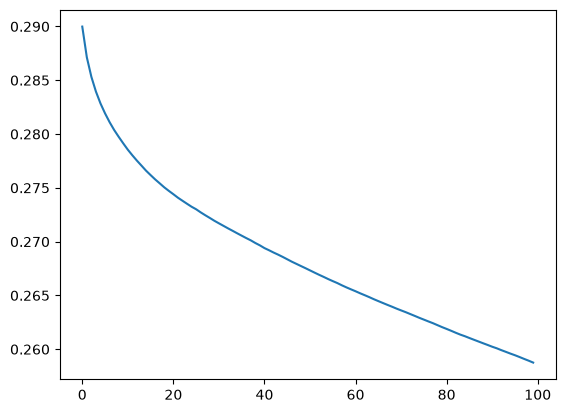

In [33]:
plt.plot(history.history['loss'])

For stochastic 

In [34]:
model.compile(loss='binary_crossentropy',metrics=['accuracy'])
#start = time.time()
# On whole data 
history = model.fit(X_scaled,y,epochs=100,batch_size=1,validation_split=0.2)
#print(time.time() - start)

Epoch 1/100


320/320 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8906 - loss: 0.2675 - val_accuracy: 0.9875 - val_loss: 0.3301
Epoch 2/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8906 - loss: 0.2666 - val_accuracy: 0.9875 - val_loss: 0.3152
Epoch 3/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8875 - loss: 0.2749 - val_accuracy: 0.9875 - val_loss: 0.3082
Epoch 4/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8906 - loss: 0.2719 - val_accuracy: 0.9875 - val_loss: 0.2972
Epoch 5/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8938 - loss: 0.2756 - val_accuracy: 0.9875 - val_loss: 0.2790
Epoch 6/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8969 - loss: 0.2767 - val_accuracy: 0.9875 - val_loss: 0.2799
Epoch 7/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8906 - loss: 0.2790 - val_accuracy: 0.9875 - val_loss: 0.2707
Epoch 8/100
320/320 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8906 - loss: 0.2742 - val_accuracy: 0.9875

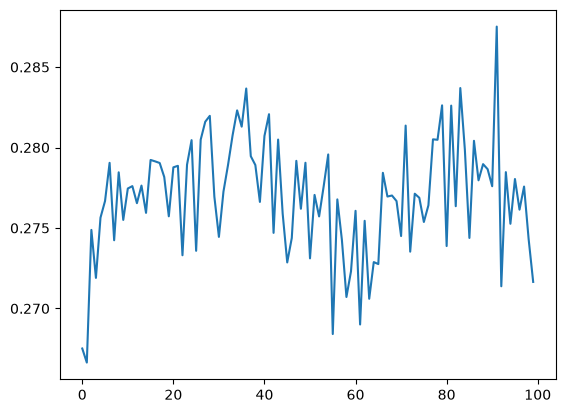

In [35]:
plt.plot(history.history['loss'])


In keras :  no of batches  = no of rows / batch_size 

that is why if we give batch_size n ie no of rows it will give no of batches as 1 ie BGD 

and in SGD batch_size 1 gives up no of batches equal to no of rows 


and in mini_batch ie in between of these two which uses the vectorization on the small batches : any other value will give some no of batches between 1 and no of rows .

We can see that loss functions reduces in unstable wayin the Stochastic and in the Batch it decreases smoothly as we can see from the graph 

So due to this zaggidness behaviour can help the SGD in the Local Minima as it can jumps out ofthe local minima and issue is that it doesnot give the actual minima but a approximate minimum 

BGD uses the vectorization ie dot product of whole batch . It is fast replacement of loops but for huge dataset RAM can be a limitations as all data needed to be loaded once in the Memory

Fast in training    :     BGD > MBGD > SGD

Convergence faster  :     SGD > MBGD > BGD  

why batch size is given in multiple of 2 : This is for the optmization as we have the data in binary keras optmizes better with divisible by 2 batch_size 

What happens is the batch size is not exactly divides the no of rows . in this case the last batch use the leftover rows only 